In [ ]:
# =============================================================================
# 1. ENVIRONMENT SETUP
# =============================================================================

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Machine Learning
from sklearn.model_selection import train_test_split, TimeSeriesSplit, cross_val_score
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.linear_model import Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
from scipy.stats import pearsonr

# Time series and feature engineering
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, f_regression

In [4]:
# Set random seed for reproducibility
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
sns.set_palette("husl")

# =============================================================================
# 2. DATA LOADING AND INITIAL EXPLORATION
# =============================================================================

In [5]:
print("\n" + "="*60)
print("DATA LOADING AND INITIAL EXPLORATION")
print("="*60)

# Load the datasets
try:
    train_df = pd.read_parquet('train.parquet')
    test_df = pd.read_parquet('test.parquet')
    sample_submission = pd.read_csv('sample_submission.csv')
    print("✓ Data loaded successfully!")
except FileNotFoundError as e:
    print(f"⚠️  Could not load data files: {e}")
    print("Please ensure train.parquet, test.parquet, and sample_submission.csv are in the working directory")
    # Create dummy data for demonstration
    print("Creating dummy data for demonstration purposes...")

    # Create dummy training data
    np.random.seed(RANDOM_SEED)
    n_train = 100000
    timestamps = pd.date_range('2023-03-01', '2024-02-29', freq='1min')[:n_train]

    train_data = {
        'timestamp': timestamps,
        'bid_qty': np.random.exponential(1000, n_train),
        'ask_qty': np.random.exponential(1000, n_train),
        'buy_qty': np.random.exponential(500, n_train),
        'sell_qty': np.random.exponential(500, n_train),
        'volume': np.random.exponential(2000, n_train),
        'label': np.random.normal(0, 1, n_train)
    }

    # Add anonymized features X_1 to X_890
    for i in range(1, 891):
        train_data[f'X_{i}'] = np.random.normal(0, 1, n_train)

    train_df = pd.DataFrame(train_data)

    # Create dummy test data
    n_test = 10000
    test_data = {
        'timestamp': range(n_test),  # Masked timestamps
        'bid_qty': np.random.exponential(1000, n_test),
        'ask_qty': np.random.exponential(1000, n_test),
        'buy_qty': np.random.exponential(500, n_test),
        'sell_qty': np.random.exponential(500, n_test),
        'volume': np.random.exponential(2000, n_test),
        'label': np.zeros(n_test)  # All zeros in test
    }

    for i in range(1, 891):
        test_data[f'X_{i}'] = np.random.normal(0, 1, n_test)

    test_df = pd.DataFrame(test_data)

    # Create sample submission
    sample_submission = pd.DataFrame({
        'ID': range(n_test),
        'label': np.zeros(n_test)
    })

    print("✓ Dummy data created for demonstration")

# Basic dataset information
print(f"\nTraining data shape: {train_df.shape}")
print(f"Test data shape: {test_df.shape}")
print(f"Sample submission shape: {sample_submission.shape}")

# Display first few rows
print("\nFirst 5 rows of training data:")
print(train_df.head())

print("\nDataset info:")
print(train_df.info())

# Check for missing values
print(f"\nMissing values in training data: {train_df.isnull().sum().sum()}")
print(f"Missing values in test data: {test_df.isnull().sum().sum()}")


DATA LOADING AND INITIAL EXPLORATION
✓ Data loaded successfully!

Training data shape: (525887, 896)
Test data shape: (538150, 896)
Sample submission shape: (538150, 2)

First 5 rows of training data:
                     bid_qty  ask_qty  buy_qty  sell_qty   volume        X1  \
timestamp                                                                     
2023-03-01 00:00:00   15.283    8.425  176.405    44.984  221.389  0.121263   
2023-03-01 00:01:00   38.590    2.336  525.846   321.950  847.796  0.302841   
2023-03-01 00:02:00    0.442   60.250  159.227   136.369  295.596  0.167462   
2023-03-01 00:03:00    4.865   21.016  335.742   124.963  460.705  0.072944   
2023-03-01 00:04:00   27.158    3.451   98.411    44.407  142.818  0.173820   

                           X2        X3        X4        X5        X6  \
timestamp                                                               
2023-03-01 00:00:00 -0.417690  0.005399  0.125948  0.058359  0.027359   
2023-03-01 00:01:00 -0.04

In [6]:
# =============================================================================
# 3. EXPLORATORY DATA ANALYSIS
# =============================================================================


EXPLORATORY DATA ANALYSIS


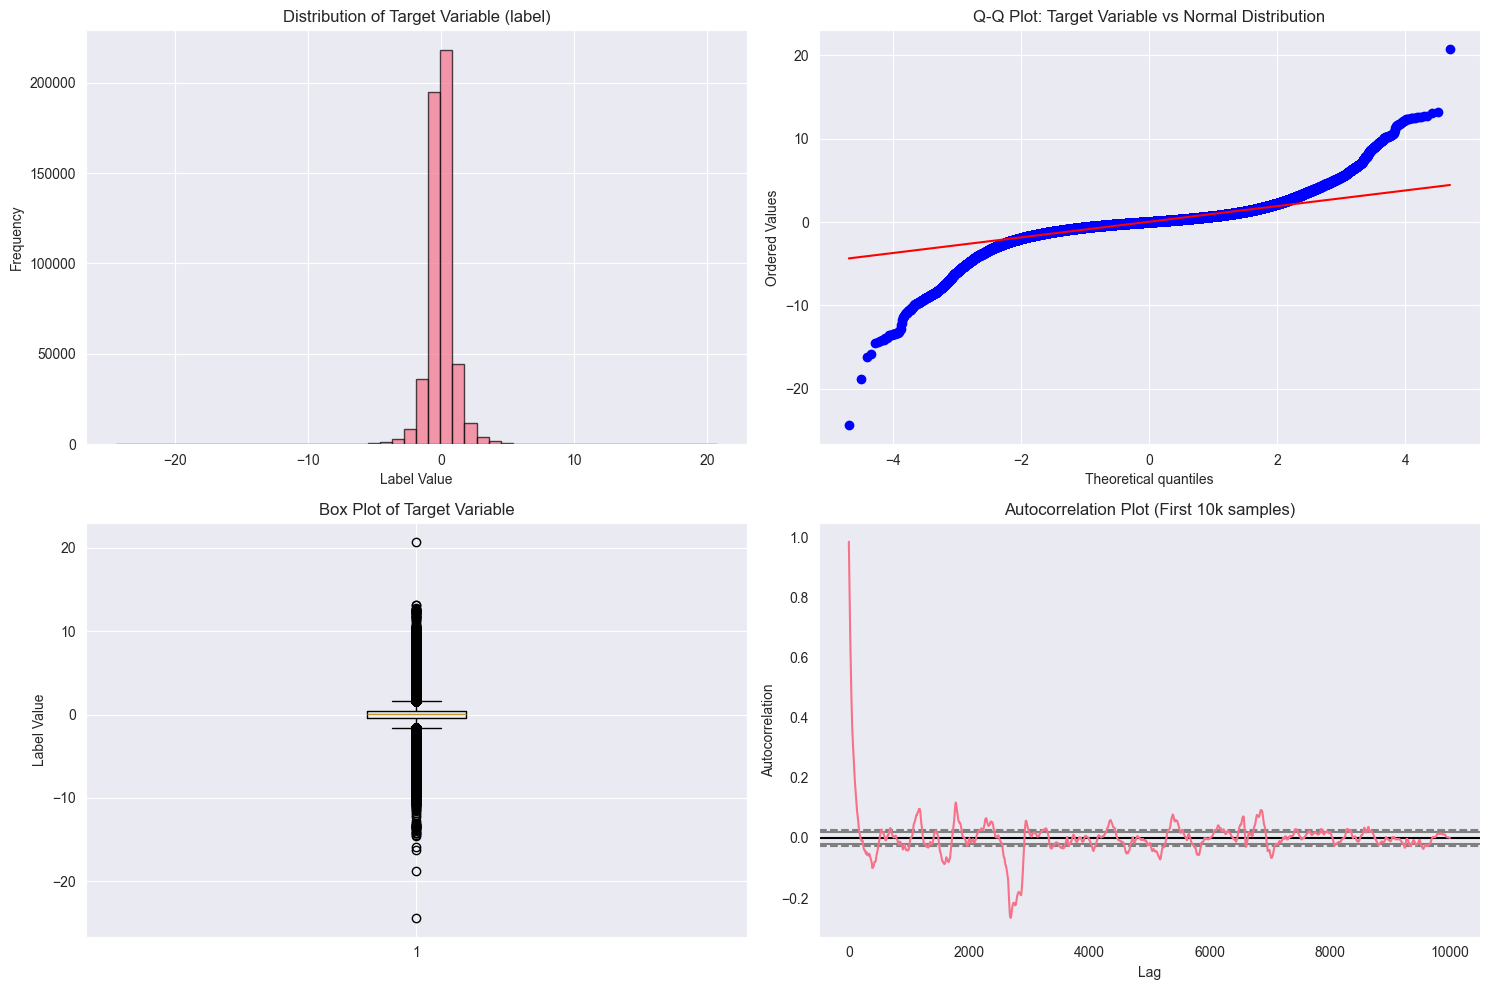


Target variable statistics:
count    525887.000000
mean          0.036126
std           1.009914
min         -24.416615
25%          -0.381585
50%           0.016262
75%           0.434135
max          20.740270
Name: label, dtype: float64


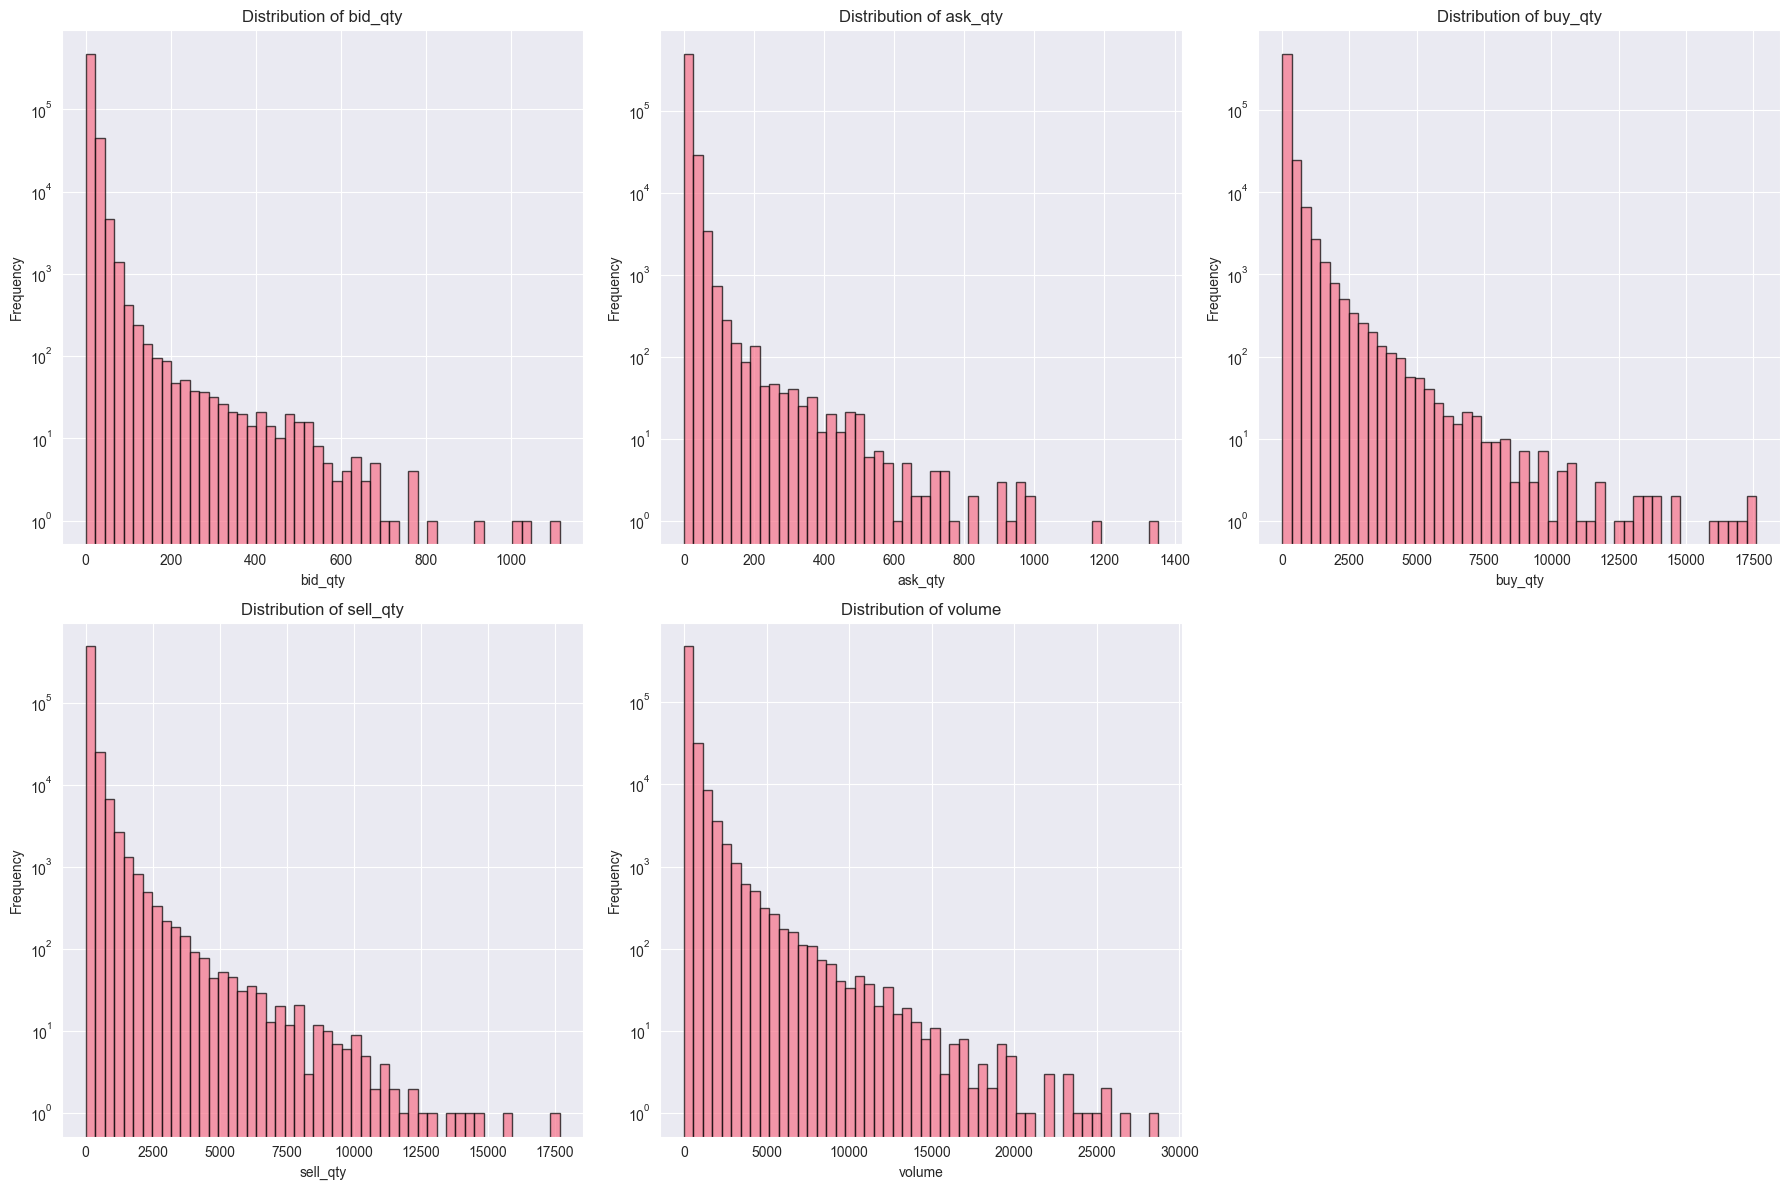


Market features statistics:
             bid_qty        ask_qty        buy_qty       sell_qty  \
count  525887.000000  525887.000000  525887.000000  525887.000000   
mean        9.968003      10.174169     131.726678     132.673944   
std        15.645741      15.889582     307.267251     309.803040   
min         0.001000       0.001000       0.000000       0.000000   
25%         2.634000       2.678000      26.407000      27.021000   
50%         6.415000       6.538000      57.015000      58.047000   
75%        13.085000      13.330000     127.639000     129.110000   
max      1114.932000    1352.965000   17614.400000   17686.234000   

              volume  
count  525887.000000  
mean      264.400622  
std       588.618746  
min         0.000000  
25%        60.688500  
50%       120.799000  
75%       256.733500  
max     28701.419000  

Correlations with target variable:
          correlation       p_value
ask_qty     -0.015762  2.938463e-30
bid_qty     -0.013220  9.042590e-2

In [7]:
print("\n" + "="*60)
print("EXPLORATORY DATA ANALYSIS")
print("="*60)

# Target variable analysis
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Distribution of target variable
axes[0, 0].hist(train_df['label'], bins=50, alpha=0.7, edgecolor='black')
axes[0, 0].set_title('Distribution of Target Variable (label)')
axes[0, 0].set_xlabel('Label Value')
axes[0, 0].set_ylabel('Frequency')

# Q-Q plot for normality check
stats.probplot(train_df['label'], dist="norm", plot=axes[0, 1])
axes[0, 1].set_title('Q-Q Plot: Target Variable vs Normal Distribution')

# Box plot
axes[1, 0].boxplot(train_df['label'])
axes[1, 0].set_title('Box Plot of Target Variable')
axes[1, 0].set_ylabel('Label Value')

# Time series plot (if timestamp is available)
if 'timestamp' in train_df.columns and pd.api.types.is_datetime64_any_dtype(train_df['timestamp']):
    # Sample every 1000th point for visualization
    sample_idx = np.arange(0, len(train_df), 1000)
    axes[1, 1].plot(train_df.iloc[sample_idx]['timestamp'], train_df.iloc[sample_idx]['label'])
    axes[1, 1].set_title('Target Variable Over Time (Sampled)')
    axes[1, 1].set_xlabel('Timestamp')
    axes[1, 1].set_ylabel('Label Value')
    plt.xticks(rotation=45)
else:
    # If timestamp is not datetime, show autocorrelation
    from pandas.plotting import autocorrelation_plot
    autocorrelation_plot(train_df['label'].iloc[:10000], ax=axes[1, 1])
    axes[1, 1].set_title('Autocorrelation Plot (First 10k samples)')

plt.tight_layout()
plt.show()

# Basic statistics
print("\nTarget variable statistics:")
print(train_df['label'].describe())

# Market features analysis
market_features = ['bid_qty', 'ask_qty', 'buy_qty', 'sell_qty', 'volume']

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for i, feature in enumerate(market_features):
    if i < len(axes):
        axes[i].hist(train_df[feature], bins=50, alpha=0.7, edgecolor='black')
        axes[i].set_title(f'Distribution of {feature}')
        axes[i].set_xlabel(feature)
        axes[i].set_ylabel('Frequency')
        axes[i].set_yscale('log')  # Log scale due to likely skewed distributions

# Remove empty subplot
if len(market_features) < len(axes):
    fig.delaxes(axes[-1])

plt.tight_layout()
plt.show()

print("\nMarket features statistics:")
print(train_df[market_features].describe())

# Correlation analysis between market features and target
correlations = {}
for feature in market_features:
    corr, p_value = pearsonr(train_df[feature], train_df['label'])
    correlations[feature] = {'correlation': corr, 'p_value': p_value}

correlation_df = pd.DataFrame(correlations).T
print("\nCorrelations with target variable:")
print(correlation_df.sort_values('correlation', key=abs, ascending=False))


In [8]:
# =============================================================================
# 4. FEATURE ENGINEERING
# =============================================================================

In [9]:
print("\n" + "="*60)
print("FEATURE ENGINEERING")
print("="*60)

def create_market_features(df):
    """Create additional market-based features"""
    df_new = df.copy()

    # Spread features
    df_new['bid_ask_spread'] = df_new['ask_qty'] - df_new['bid_qty']
    df_new['bid_ask_ratio'] = df_new['bid_qty'] / (df_new['ask_qty'] + 1e-8)

    # Volume features
    df_new['buy_sell_ratio'] = df_new['buy_qty'] / (df_new['sell_qty'] + 1e-8)
    df_new['buy_volume_ratio'] = df_new['buy_qty'] / (df_new['volume'] + 1e-8)
    df_new['sell_volume_ratio'] = df_new['sell_qty'] / (df_new['volume'] + 1e-8)

    # Imbalance features
    df_new['quantity_imbalance'] = (df_new['bid_qty'] - df_new['ask_qty']) / (df_new['bid_qty'] + df_new['ask_qty'] + 1e-8)
    df_new['trade_imbalance'] = (df_new['buy_qty'] - df_new['sell_qty']) / (df_new['buy_qty'] + df_new['sell_qty'] + 1e-8)

    return df_new

def create_statistical_features(df, feature_cols, windows=[5, 10, 20]):
    """Create rolling statistical features"""
    df_new = df.copy()

    for col in feature_cols[:5]:  # Limit to first 5 features for speed
        for window in windows:
            df_new[f'{col}_rolling_mean_{window}'] = df[col].rolling(window=window, min_periods=1).mean()
            df_new[f'{col}_rolling_std_{window}'] = df[col].rolling(window=window, min_periods=1).std()
            df_new[f'{col}_rolling_max_{window}'] = df[col].rolling(window=window, min_periods=1).max()
            df_new[f'{col}_rolling_min_{window}'] = df[col].rolling(window=window, min_periods=1).min()

    return df_new

# Apply feature engineering to training data
print("Creating market-based features...")
train_engineered = create_market_features(train_df)

print("Creating statistical features...")
# Get X feature columns
x_features = [col for col in train_df.columns if col.startswith('X_')]
print(f"Found {len(x_features)} anonymized features")

# Create statistical features for a subset of X features (for speed)
selected_x_features = x_features[:10]  # Use first 10 X features for demonstration
train_engineered = create_statistical_features(train_engineered, selected_x_features)

print(f"Engineering complete. New shape: {train_engineered.shape}")

# Apply same transformations to test data
test_engineered = create_market_features(test_df)
test_engineered = create_statistical_features(test_engineered, selected_x_features)

print("Feature engineering completed for both train and test sets")



FEATURE ENGINEERING
Creating market-based features...
Creating statistical features...
Found 0 anonymized features
Engineering complete. New shape: (525887, 903)
Feature engineering completed for both train and test sets


In [10]:
# =============================================================================
# 5. FEATURE SELECTION AND PREPROCESSING
# =============================================================================

In [11]:
print("\n" + "="*60)
print("FEATURE SELECTION AND PREPROCESSING")
print("="*60)

# Prepare features for modeling
feature_cols = [col for col in train_engineered.columns if col not in ['timestamp', 'label']]
X = train_engineered[feature_cols].fillna(0)  # Fill NaN values
y = train_engineered['label']

print(f"Total features available: {len(feature_cols)}")

# Remove constant features
constant_features = [col for col in feature_cols if X[col].nunique() <= 1]
if constant_features:
    print(f"Removing {len(constant_features)} constant features")
    feature_cols = [col for col in feature_cols if col not in constant_features]
    X = X[feature_cols]

# Feature selection using correlation with target
print("Performing feature selection...")

# Calculate correlations with target
feature_correlations = {}
for col in feature_cols:
    if X[col].nunique() > 1:  # Skip constant features
        corr, p_value = pearsonr(X[col], y)
        if not np.isnan(corr):
            feature_correlations[col] = abs(corr)

# Select top features
top_features = sorted(feature_correlations.items(), key=lambda x: x[1], reverse=True)
selected_features = [feat[0] for feat in top_features[:100]]  # Top 100 features

print(f"Selected {len(selected_features)} features based on correlation with target")
print("\nTop 10 features by correlation:")
for i, (feat, corr) in enumerate(top_features[:10]):
    print(f"{i+1:2d}. {feat}: {corr:.4f}")



FEATURE SELECTION AND PREPROCESSING
Total features available: 902
Removing 27 constant features
Performing feature selection...
Selected 100 features based on correlation with target

Top 10 features by correlation:
 1. X21: 0.0694
 2. X20: 0.0677
 3. X28: 0.0641
 4. X863: 0.0641
 5. X29: 0.0623
 6. X19: 0.0623
 7. X27: 0.0623
 8. X22: 0.0577
 9. X858: 0.0573
10. X219: 0.0567


In [12]:
# =============================================================================
# 6. MODEL DEVELOPMENT AND TRAINING
# =============================================================================

In [13]:
print("\n" + "="*60)
print("MODEL DEVELOPMENT AND TRAINING")
print("="*60)

# Prepare final dataset
X_selected = X[selected_features]
X_test_selected = test_engineered[selected_features].fillna(0)

# Split data for validation (time-aware split)
split_idx = int(0.8 * len(X_selected))
X_train, X_val = X_selected[:split_idx], X_selected[split_idx:]
y_train, y_val = y[:split_idx], y[split_idx:]

print(f"Training set size: {X_train.shape}")
print(f"Validation set size: {X_val.shape}")

# Scale features
scaler = RobustScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test_selected)

# Define models to try
models = {
    'Ridge': Ridge(alpha=1.0, random_state=RANDOM_SEED),
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=RANDOM_SEED, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=100, random_state=RANDOM_SEED)
}

# Train and evaluate models
results = {}
trained_models = {}

for name, model in models.items():
    print(f"\nTraining {name}...")

    # Train model
    if name == 'Ridge':
        model.fit(X_train_scaled, y_train)
        val_pred = model.predict(X_val_scaled)
    else:
        model.fit(X_train, y_train)
        val_pred = model.predict(X_val)

    # Calculate metrics
    mse = mean_squared_error(y_val, val_pred)
    mae = mean_absolute_error(y_val, val_pred)
    corr, _ = pearsonr(y_val, val_pred)

    results[name] = {
        'MSE': mse,
        'MAE': mae,
        'Correlation': corr
    }

    trained_models[name] = model

    print(f"  MSE: {mse:.6f}")
    print(f"  MAE: {mae:.6f}")
    print(f"  Correlation: {corr:.6f}")

# Select best model based on correlation (competition metric)
best_model_name = max(results.keys(), key=lambda x: results[x]['Correlation'])
best_model = trained_models[best_model_name]

print(f"\nBest model: {best_model_name}")
print(f"Best correlation: {results[best_model_name]['Correlation']:.6f}")


MODEL DEVELOPMENT AND TRAINING
Training set size: (420709, 100)
Validation set size: (105178, 100)

Training Ridge...
  MSE: 1.166460
  MAE: 0.745163
  Correlation: 0.117454

Training Random Forest...
  MSE: 2.021040
  MAE: 0.892884
  Correlation: 0.061980

Training Gradient Boosting...
  MSE: 1.578016
  MAE: 0.790204
  Correlation: 0.062257

Best model: Ridge
Best correlation: 0.117454


In [14]:
# =============================================================================
# 7. FINAL PREDICTIONS AND SUBMISSION
# =============================================================================

In [16]:
print("\n" + "="*60)
print("FINAL PREDICTIONS AND SUBMISSION")
print("="*60)

# Make predictions on test set
if best_model_name == 'Ridge':
    test_predictions = best_model.predict(X_test_scaled)
else:
    test_predictions = best_model.predict(X_test_selected)

print(f"Generated {len(test_predictions)} test predictions")
print(f"Prediction statistics:")
print(f"  Mean: {np.mean(test_predictions):.6f}")
print(f"  Std: {np.std(test_predictions):.6f}")
print(f"  Min: {np.min(test_predictions):.6f}")
print(f"  Max: {np.max(test_predictions):.6f}")

# Create submission file
submission = sample_submission.copy()
submission['label'] = test_predictions

# Save submission
submission.to_csv('submission.csv', index=False)
print("\n✓ Submission saved as 'submission.csv'")

# Display submission format
print("\nSubmission preview:")
print(submission.head(10))


FINAL PREDICTIONS AND SUBMISSION
Generated 538150 test predictions
Prediction statistics:
  Mean: -0.096967
  Std: 0.407632
  Min: -3.968905
  Max: 3.711400

✓ Submission saved as 'submission.csv'

Submission preview:
   ID  prediction     label
0   1   -0.280233  0.065399
1   2    1.371969  0.038546
2   3   -2.045252 -0.065116
3   4   -1.447555 -0.167756
4   5   -1.303901  0.195493
5   6    1.659284 -0.554867
6   7    1.376758 -0.596850
7   8    0.237542 -0.332866
8   9   -0.101127  0.890309
9  10    1.267094 -0.335869
